
# Notebook 2: EfficientNetV2-S — Binary Classifier

## Why EfficientNetV2-S?
EfficientNetV2-S is the modern successor to EfficientNet-B3.
- Trains **2-4x faster** than EfficientNet-B3 due to Fused-MBConv blocks
- Achieves **higher ImageNet accuracy** with fewer parameters
- Excellent at fine-grained texture extraction (pigment networks, borders)
- Pre-trained on ImageNet-21K → very strong transfer learning base

## Training Strategy
| Component | Choice | Reason |
|---|---|---|
| Loss Function | **Focal Loss** | Handles class imbalance better than BCE |
| Optimizer | **AdamW** | Weight decay prevents overfitting |
| LR Scheduler | **CosineAnnealingLR** | Smooth convergence |
| Mixed Precision | **torch.cuda.amp** | ~40% speedup on Kaggle GPU |
| Augmentation | Flip + Rotate + ColorJitter | Forces model to learn features, not artifacts |
| Checkpointing | Best Val AUC | Saves the single best epoch's weights |
| Early Stopping | Patience = 7 | Prevents Kaggle session timeout waste |

In [1]:
# ── CODE CELL 1: Install & Import ─────────────────────────────────────
import os
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from PIL import Image
from tqdm import tqdm

import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import Dataset, DataLoader
from torch.cuda.amp import GradScaler, autocast
import torchvision.transforms as T
import timm

from sklearn.metrics import (roc_auc_score, confusion_matrix,
                              classification_report, roc_curve)

# ── Reproducibility seed ──
SEED = 42
torch.manual_seed(SEED)
np.random.seed(SEED)

DEVICE    = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f"🖥️  Device: {DEVICE}")
if torch.cuda.is_available():
    print(f"   GPU: {torch.cuda.get_device_name(0)}")
    print(f"   VRAM: {torch.cuda.get_device_properties(0).total_memory / 1e9:.1f} GB")


🖥️  Device: cuda
   GPU: Tesla T4
   VRAM: 15.6 GB



## Configuration
All hyperparameters are centralized here.
Change only these values if you want to experiment.


In [2]:
# ── CODE CELL 2: Hyperparameter Config ────────────────────────────────
# ── Input Paths (update to match your Notebook 1 output dataset)
INPUT_CSV_DIR = '/kaggle/input/notebooks/nandini143/data-preparation'   # ← Add Notebook 1 output as input
OUTPUT_DIR    = '/kaggle/working/'

# ── Training Hyperparameters
IMG_SIZE      = 384
BATCH_SIZE    = 16     # Reduce to 16 if you get OOM error
NUM_EPOCHS    = 30
LR            = 1e-4
WEIGHT_DECAY  = 1e-2
PATIENCE      = 7      # Early stopping patience (epochs)
WARMUP_EPOCHS = 2      # Gradual unfreezing: backbone frozen for first N epochs
MODEL_NAME    = 'tf_efficientnetv2_s'
SAVE_PATH     = os.path.join(OUTPUT_DIR, 'efficientnetv2s_best.pth')

print("=" * 55)
print(f"  Model         : {MODEL_NAME}")
print(f"  Image Size    : {IMG_SIZE}x{IMG_SIZE}")
print(f"  Batch Size    : {BATCH_SIZE}")
print(f"  Max Epochs    : {NUM_EPOCHS}")
print(f"  Learning Rate : {LR}")
print(f"  Warmup Epochs : {WARMUP_EPOCHS} (backbone frozen during warmup)")
print(f"  Early Stop    : patience={PATIENCE}")
print("=" * 55)
# ── Multi-Modal Metadata Config (Phase 2 upgrade) ─────────────────────────
# META_DIM = number of metadata features from data-preparation.ipynb
# = age_norm(1) + sex_encoded(1) + site_one_hot(9) = 11
META_DIM    = 11
META_HIDDEN = 32   # Hidden units in the Tabular MLP branch
USE_CUTMIX  = True  # Enable CutMix/MixUp during training
CUTMIX_PROB = 0.3   # Probability of applying CutMix per batch


  Model         : tf_efficientnetv2_s
  Image Size    : 384x384
  Batch Size    : 16
  Max Epochs    : 30
  Learning Rate : 0.0001
  Warmup Epochs : 2 (backbone frozen during warmup)
  Early Stop    : patience=7


## Dataset & DataLoader
We use a custom PyTorch `Dataset` class that:
- Loads pre-processed images from disk
- Applies augmentation **only** to the training set
- Returns (image tensor, label) pairs

In [3]:
# ── CODE CELL 3: Custom Dataset Class (MULTI-MODAL) ──────────────────────────
# Phase 2 upgrade: Dataset now returns (image, metadata_vector, label)
# metadata_vector contains: age_norm, sex_encoded, site_* (11 features total)

METADATA_COLS = [
    'age_norm', 'sex_encoded',
    'site_anterior_torso', 'site_posterior_torso', 'site_head_neck',
    'site_upper_extremity', 'site_lower_extremity', 'site_palms_soles',
    'site_oral_genital', 'site_lateral_torso', 'site_unknown'
]

class ISICDataset(Dataset):
    """
    ISIC 2019 Multi-Modal Dataset.
    Returns (image_tensor, metadata_tensor, label_tensor).
    """
    def __init__(self, df: pd.DataFrame, transform, is_train: bool = True):
        self.df       = df.reset_index(drop=True)
        self.transform = transform
        self.is_train  = is_train
        # Check which metadata cols are available in the dataframe
        self.meta_cols = [c for c in METADATA_COLS if c in df.columns]
        if len(self.meta_cols) == 0:
            print("  WARNING: No metadata columns found in CSV! Using zeros.")
        else:
            print(f"  Dataset loaded: {len(df)} rows | {len(self.meta_cols)} metadata features")

    def __len__(self):
        return len(self.df)

    def __getitem__(self, idx):
        row   = self.df.iloc[idx]
        image = Image.open(row['image_path']).convert('RGB')
        image = self.transform(image)
        label = torch.tensor(row['binary_label'], dtype=torch.float32)

        # Build metadata vector (zeros if cols missing)
        if self.meta_cols:
            meta = torch.tensor(
                row[self.meta_cols].values.astype('float32'),
                dtype=torch.float32
            )
        else:
            meta = torch.zeros(META_DIM, dtype=torch.float32)

        return image, meta, label


In [4]:
# ── CODE CELL 4: Augmentation Transforms (CLAHE + CoarseDropout added) ───────
#
# PHASE 2 UPGRADES:
#   1. CLAHE — Contrast Limited Adaptive Histogram Equalization
#      Enhances micro-structures in skin (pigment networks, dots) by
#      normalizing local contrast. Standardizes lighting across images.
#   2. CoarseDropout — Drops small random black squares on the image.
#      Forces the model to look past thick hair, smudges, and occlusions.
#
# We use albumentations for CLAHE/CoarseDropout, then convert to tensor.

import albumentations as A
from albumentations.pytorch import ToTensorV2
import cv2
import numpy as np 

IMAGENET_MEAN = [0.485, 0.456, 0.406]
IMAGENET_STD  = [0.229, 0.224, 0.225]

# Train augmentation (albumentations pipeline)
train_albu = A.Compose([
    A.Resize(int(IMG_SIZE * 1.12), int(IMG_SIZE * 1.12)),
    A.RandomCrop(IMG_SIZE, IMG_SIZE),
    A.HorizontalFlip(p=0.5),
    A.VerticalFlip(p=0.5),
    A.RandomRotate90(p=0.5),
    A.ColorJitter(brightness=0.2, contrast=0.2, saturation=0.1, hue=0.05, p=0.5),
    A.ShiftScaleRotate(shift_limit=0.05, scale_limit=0.2, rotate_limit=15, p=0.5),
    # ── PHASE 2: CLAHE — histogram equalization for better feature visibility
    A.CLAHE(clip_limit=4.0, tile_grid_size=(8, 8), p=0.4),
    # ── PHASE 2: CoarseDropout — simulates hair / occlusion robustness
    A.CoarseDropout(max_holes=8, max_height=32, max_width=32,
                    min_holes=1, fill_value=0, p=0.4),
    A.Normalize(mean=IMAGENET_MEAN, std=IMAGENET_STD),
    ToTensorV2(),
])

# Val/Test (no augmentation)
val_albu = A.Compose([
    A.Resize(IMG_SIZE, IMG_SIZE),
    A.Normalize(mean=IMAGENET_MEAN, std=IMAGENET_STD),
    ToTensorV2(),
])

# Wrapper: ISICDataset uses PIL images; albumentations needs numpy arrays
class AlbuTransform:
    def __init__(self, albu_pipeline):
        self.pipeline = albu_pipeline
    def __call__(self, pil_img):
        img_np = np.array(pil_img)  # PIL -> numpy HWC uint8
        result = self.pipeline(image=img_np)
        return result['image']      # returns CHW float tensor

train_transforms = AlbuTransform(train_albu)
val_transforms   = AlbuTransform(val_albu)

print("Augmentation pipeline (Phase 2 multi-modal):")
print("  Train: Resize -> Crop -> Flip -> Rotate -> ColorJitter -> CLAHE -> CoarseDropout -> Normalize")
print("  Val  : Resize -> Normalize")


Augmentation pipeline (Phase 2 multi-modal):
  Train: Resize -> Crop -> Flip -> Rotate -> ColorJitter -> CLAHE -> CoarseDropout -> Normalize
  Val  : Resize -> Normalize


/usr/local/lib/python3.12/dist-packages/albumentations/core/validation.py:114: UserWarning: ShiftScaleRotate is a special case of Affine transform. Please use Affine transform instead.
  original_init(self, **validated_kwargs)
/tmp/ipykernel_23/1076743866.py:32: UserWarning: Argument(s) 'max_holes, max_height, max_width, min_holes, fill_value' are not valid for transform CoarseDropout
  A.CoarseDropout(max_holes=8, max_height=32, max_width=32,


## Phase 2: Multi-Modal Architecture, CutMix & CLAHE

This section introduces the three major Phase 2 upgrades:
1. **Multi-Modal Architecture** — EfficientNetV2-S backbone fused with a Tabular MLP
2. **CLAHE + CoarseDropout** — applied in the augmentation pipeline above
3. **CutMix / MixUp** — stochastic label-blending regularization during training

In [5]:
# ── PHASE 2: Multi-Modal Architecture (Mid-Fusion) ───────────────────────────
#
# Architecture:
#   Branch 1 (Vision)  : EfficientNetV2-S backbone -> 1280 features
#   Branch 2 (Tabular) : Small MLP processes metadata -> META_HIDDEN features
#   Fusion             : Concatenate -> Dropout -> Linear(1)
#
# Why Mid-Fusion (not Late-Fusion)?
#   Mid-fusion lets the final classifier jointly learn from both modalities.
#   Late-fusion (averaging probs after separate models) cannot learn
#   interactions like "if patient is old AND lesion is on head -> higher risk".

import timm

class TabularMLP(nn.Module):
    """Small MLP that processes the metadata vector into a dense embedding."""
    def __init__(self, in_dim, hidden_dim, out_dim, dropout=0.3):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(in_dim, hidden_dim),
            nn.BatchNorm1d(hidden_dim),
            nn.GELU(),
            nn.Dropout(dropout),
            nn.Linear(hidden_dim, out_dim),
            nn.GELU(),
        )
    def forward(self, x):
        return self.net(x)

class MultiModalEfficientNet(nn.Module):
    """
    EfficientNetV2-S + Patient Metadata Multi-Modal Classifier.
    """
    def __init__(self, backbone_name='tf_efficientnetv2_s', meta_dim=11,
                 meta_hidden=32, dropout=0.4, pretrained=True):
        super().__init__()

        # ── Vision backbone (EfficientNetV2-S)
        backbone = timm.create_model(backbone_name, pretrained=pretrained, num_classes=0)
        img_feat_dim = backbone.num_features   # 1280 for EfficientNetV2-S
        self.backbone = backbone

        # ── Tabular MLP
        self.meta_mlp = TabularMLP(meta_dim, meta_hidden, meta_hidden, dropout=0.3)

        # ── Fusion head
        fusion_dim = img_feat_dim + meta_hidden
        self.head = nn.Sequential(
            nn.Dropout(dropout),
            nn.Linear(fusion_dim, 256),
            nn.BatchNorm1d(256),
            nn.GELU(),
            nn.Dropout(dropout * 0.5),
            nn.Linear(256, 1)
        )

    def forward(self, images, meta):
        img_feats  = self.backbone(images)          # (B, 1280)
        meta_feats = self.meta_mlp(meta)            # (B, 32)
        fused      = torch.cat([img_feats, meta_feats], dim=1)  # (B, 1312)
        return self.head(fused).squeeze(1)          # (B,)

# ── CODE CELL 7: Initialize Multi-Modal EfficientNetV2-S (FIXED) ───
# Clean any old reference from environment memory
if 'model' in locals(): 
    del model 

# Re-instantiate the actual Multi-Modal class from Phase 2
model = MultiModalEfficientNet(
    backbone_name=MODEL_NAME,
    meta_dim=META_DIM,
    meta_hidden=META_HIDDEN,
    dropout=0.4,
    pretrained=True
).to(DEVICE)

# ── Gradual Unfreezing Configuration Helpers ─────────────────────────
def freeze_backbone(m: nn.Module) -> None:
    """Freeze all backbone parameters. Only the custom head and tabular MLP will train."""
    for p in m.backbone.parameters():
        p.requires_grad = False

def unfreeze_all(m: nn.Module) -> None:
    """Unfreeze all parameters for full fine-tuning."""
    for p in m.parameters():
        p.requires_grad = True

# Phase 1 Initial State: Lock down backbone for the warmup phase
freeze_backbone(model)

total_params  = sum(p.numel() for p in model.parameters())
warmup_params = sum(p.numel() for p in model.parameters() if p.requires_grad)

print(f"✅ True Multi-Modal Model Variant Active: {type(model).__name__}")
print(f"   Total Parameters              : {total_params:,}")
print(f"   Trainable (Warmup — head only): {warmup_params:,}")
print(f"   🔒 Backbone FROZEN for first {WARMUP_EPOCHS} epoch(s).")

model.safetensors:   0%|          | 0.00/86.5M [00:00<?, ?B/s]

✅ True Multi-Modal Model Variant Active: MultiModalEfficientNet
   Total Parameters              : 20,515,889
   Trainable (Warmup — head only): 338,401
   🔒 Backbone FROZEN for first 2 epoch(s).


In [6]:
# ── PHASE 2: CutMix & MixUp Helpers ─────────────────────────────────────────
#
# CutMix: Cuts a rectangular patch from image B and pastes it onto image A.
#         Label becomes a blend: e.g., 0.7*label_A + 0.3*label_B
# MixUp:  Blends the entire image: new_img = 0.8*A + 0.2*B
#         Label: 0.8*label_A + 0.2*label_B
#
# Why this helps accuracy:
#   The model can no longer memorize "if I see THIS exact texture, it's cancer."
#   It must learn structural, global features -> generalizes much better.

import numpy as np

def rand_bbox(size, lam):
    """Returns random bounding box for CutMix."""
    W, H  = size[2], size[3]
    cut_r = np.sqrt(1.0 - lam)
    cut_w = int(W * cut_r)
    cut_h = int(H * cut_r)
    cx = np.random.randint(W)
    cy = np.random.randint(H)
    x1 = np.clip(cx - cut_w // 2, 0, W)
    y1 = np.clip(cy - cut_h // 2, 0, H)
    x2 = np.clip(cx + cut_w // 2, 0, W)
    y2 = np.clip(cy + cut_h // 2, 0, H)
    return x1, y1, x2, y2

def apply_cutmix_or_mixup(images, labels, meta, prob=0.3):
    """
    Randomly applies CutMix or MixUp with probability `prob`.
    Returns (mixed_images, mixed_labels, mixed_meta).
    """
    if not USE_CUTMIX or np.random.rand() > prob:
        return images, labels, meta

    batch_size = images.size(0)
    lam = np.random.beta(1.0, 1.0)
    rand_idx = torch.randperm(batch_size, device=images.device)

    mixed_labels = lam * labels + (1 - lam) * labels[rand_idx]
    mixed_meta   = lam * meta   + (1 - lam) * meta[rand_idx]

    if np.random.rand() > 0.5:
        # CutMix
        x1, y1, x2, y2 = rand_bbox(images.size(), lam)
        mixed_images = images.clone()
        mixed_images[:, :, y1:y2, x1:x2] = images[rand_idx, :, y1:y2, x1:x2]
        # Adjust lambda based on actual cut size
        lam = 1 - (x2 - x1) * (y2 - y1) / (images.size(2) * images.size(3))
        mixed_labels = lam * labels + (1 - lam) * labels[rand_idx]
    else:
        # MixUp
        mixed_images = lam * images + (1 - lam) * images[rand_idx]

    return mixed_images, mixed_labels, mixed_meta

print("CutMix + MixUp helpers ready.")
print(f"  USE_CUTMIX = {USE_CUTMIX}  |  CUTMIX_PROB = {CUTMIX_PROB}")


CutMix + MixUp helpers ready.
  USE_CUTMIX = True  |  CUTMIX_PROB = 0.3


In [7]:
# ── CODE CELL 5: Load Data (UPDATED) ───────────────────────────────────

# Load the CSVs
train_df = pd.read_csv(f'{INPUT_CSV_DIR}/binary_train.csv')
val_df   = pd.read_csv(f'{INPUT_CSV_DIR}/binary_val.csv')
test_df  = pd.read_csv(f'{INPUT_CSV_DIR}/binary_test.csv')

# 🔧 THE FIX: Dynamically update the file paths in memory
# Swap the old Notebook 1 path for the new Notebook 2 input path
OLD_PATH = '/kaggle/working/preprocessed/'
NEW_PATH = f'{INPUT_CSV_DIR}/preprocessed/'

train_df['image_path'] = train_df['image_path'].str.replace(OLD_PATH, NEW_PATH)
val_df['image_path']   = val_df['image_path'].str.replace(OLD_PATH, NEW_PATH)
test_df['image_path']  = test_df['image_path'].str.replace(OLD_PATH, NEW_PATH)

# Proceed with Dataset initialization using the corrected dataframes
train_dataset = ISICDataset(train_df, train_transforms, is_train=True)
val_dataset   = ISICDataset(val_df,   val_transforms,   is_train=False)
test_dataset  = ISICDataset(test_df,  val_transforms,   is_train=False)

train_loader = DataLoader(train_dataset, batch_size=BATCH_SIZE,
                          shuffle=True,  num_workers=4, pin_memory=True)
val_loader   = DataLoader(val_dataset,   batch_size=BATCH_SIZE,
                          shuffle=False, num_workers=4, pin_memory=True)
test_loader  = DataLoader(test_dataset,  batch_size=BATCH_SIZE,
                          shuffle=False, num_workers=4, pin_memory=True)

print(f"\n📦 DataLoaders ready:")
print(f"   Train batches : {len(train_loader):>4} ({len(train_dataset):,} images)")
print(f"   Val batches   : {len(val_loader):>4} ({len(val_dataset):,} images)")
print(f"   Test batches  : {len(test_loader):>4} ({len(test_dataset):,} images)")
print("DataLoaders ready (multi-modal: 3-item batches: image, meta, label)")


  Dataset loaded: 20264 rows | 11 metadata features
  Dataset loaded: 2533 rows | 11 metadata features
  Dataset loaded: 2534 rows | 11 metadata features

📦 DataLoaders ready:
   Train batches : 1267 (20,264 images)
   Val batches   :  159 (2,533 images)
   Test batches  :  159 (2,534 images)
DataLoaders ready (multi-modal: 3-item batches: image, meta, label)


## Focal Loss
Binary Cross-Entropy tends to ignore hard, misclassified examples.
**Focal Loss** adds a modulating factor `(1 - p)^gamma` so the model
focuses learning on the difficult, uncertain samples.

This is particularly important for clinical AI where the hard cases
(borderline malignant lesions) are the most critical to get right.

In [8]:
# ── CODE CELL 6: Focal Loss with Label Smoothing ────────────────
class FocalLoss(nn.Module):
    """
    Focal Loss for Binary Classification with Label Smoothing.
    FL(p) = -alpha * (1 - p)^gamma * log(p)
    Label smoothing softens hard targets (0 -> eps/2, 1 -> 1 - eps/2)
    to prevent overconfidence and reduce overfitting.
    ✔ FIXED: label_smoothing reduced from 0.1 -> 0.02.
       0.1 forces the model to be 10% uncertain on every prediction,
       which causes underfitting on rare malignant cases.
    """
    def __init__(self, alpha: float = 0.25, gamma: float = 2.0,
                 label_smoothing: float = 0.02):
        super().__init__()
        self.alpha           = alpha
        self.gamma           = gamma
        self.label_smoothing = label_smoothing

    def forward(self, logits: torch.Tensor,
                targets: torch.Tensor) -> torch.Tensor:
        # Label smoothing: soften 0 -> ls/2, soften 1 -> 1 - ls/2
        if self.label_smoothing > 0:
            targets = targets * (1 - self.label_smoothing) + self.label_smoothing / 2

        bce   = nn.functional.binary_cross_entropy_with_logits(
                    logits, targets, reduction='none')
        probs = torch.sigmoid(logits)
        p_t   = probs * targets + (1 - probs) * (1 - targets)
        alpha = self.alpha * targets + (1 - self.alpha) * (1 - targets)
        focal = alpha * (1 - p_t) ** self.gamma * bce
        return focal.mean()

print("✅ FocalLoss with Label Smoothing=0.02 defined.")


✅ FocalLoss with Label Smoothing=0.02 defined.


## Training Loop with Gradual Unfreezing
Key features of our training loop:
- **Gradual Unfreezing (Epochs 1-2):** Backbone is FROZEN. Only the custom
  classification head is trained. This prevents the pretrained ImageNet weights
  from being destroyed by the randomly-initialized head's large initial gradients.
- **Full Fine-Tuning (Epoch 3+):** All layers are unfrozen. The entire backbone
  adapts slowly to dermoscopy images using a carefully calibrated LR.
- **Mixed Precision (AMP):** Halves VRAM usage and speeds up training ~40%
- **Gradient Clipping:** Prevents exploding gradients
- **Per-Epoch Checkpointing:** Saves model if validation AUC improves
- **Early Stopping:** Stops training if no improvement for `PATIENCE` epochs


In [9]:
# ── CODE CELL 8: Training Utilities & Setup (FIXED) ───────────────────────────
criterion = FocalLoss(alpha=0.35, gamma=2.0, label_smoothing=0.02)
optimizer = optim.AdamW(model.parameters(), lr=LR, weight_decay=WEIGHT_DECAY)
scheduler = optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=NUM_EPOCHS, eta_min=1e-6)
scaler    = torch.amp.GradScaler('cuda')   

ACCUMULATION_STEPS = 2

def train_one_epoch(model, loader, optimizer, criterion, scaler, device):
    model.train()
    running_loss = 0.0
    all_labels, all_probs = [], []
    correct, total = 0, 0

    optimizer.zero_grad(set_to_none=True)

    for step, (images, meta, labels) in enumerate(tqdm(loader, desc="  Training", leave=False)):
        images = images.to(device, non_blocking=True)
        labels = labels.to(device, non_blocking=True)
        meta   = meta.to(device, non_blocking=True)  # ✅ FIXED: Ensured metadata is on GPU
        
        images, labels, meta = apply_cutmix_or_mixup(images, labels, meta, prob=CUTMIX_PROB)

        # ✅ FIXED: Used modern non-deprecated AMP autocast context
        with torch.amp.autocast('cuda'):
            logits = model(images, meta)
            loss   = criterion(logits, labels)

        loss_scaled = loss / ACCUMULATION_STEPS
        scaler.scale(loss_scaled).backward()

        if (step + 1) % ACCUMULATION_STEPS == 0 or (step + 1) == len(loader):
            scaler.unscale_(optimizer)
            torch.nn.utils.clip_grad_norm_(model.parameters(), max_norm=1.0)
            scaler.step(optimizer)
            scaler.update()
            optimizer.zero_grad(set_to_none=True)

        running_loss += loss.item() * images.size(0)
        probs_batch   = torch.sigmoid(logits).detach().cpu().numpy()
        all_probs.extend(probs_batch)
        raw_labels = (labels > 0.5).long().cpu().numpy()
        all_labels.extend(raw_labels)

        preds    = (torch.sigmoid(logits) >= 0.5).long()
        correct += (preds == (labels >= 0.5).long()).sum().item()
        total   += labels.size(0)

    # ✅ FIXED: Convert soft continuous CutMix targets back to hard binary integers for metrics engine
    hard_labels = [1 if l >= 0.5 else 0 for l in all_labels]
    epoch_loss = running_loss / len(loader.dataset)
    epoch_auc  = roc_auc_score(hard_labels, all_probs)
    epoch_acc  = correct / total
    return epoch_loss, epoch_auc, epoch_acc

def validate(model, loader, criterion, device):
    model.eval()
    running_loss = 0.0
    all_labels, all_probs = [], []
    correct, total = 0, 0

    with torch.no_grad():
        for images, meta, labels in tqdm(loader, desc="  Validating", leave=False):
            images = images.to(device, non_blocking=True)
            meta   = meta.to(device, non_blocking=True)  # ✅ FIXED: Resolved string-split parentheses error
            labels = labels.to(device, non_blocking=True)

            # ✅ FIXED: Used modern non-deprecated AMP autocast context
            with torch.amp.autocast('cuda'):
                logits = model(images, meta)
                loss   = criterion(logits, labels)

            running_loss += loss.item() * images.size(0)
            probs_batch   = torch.sigmoid(logits).cpu().numpy()
            all_probs.extend(probs_batch)
            all_labels.extend(labels.cpu().numpy())

            preds    = (torch.sigmoid(logits) >= 0.5).long()
            correct += (preds == labels.long()).sum().item()
            total   += labels.size(0)

    epoch_loss = running_loss / len(loader.dataset)
    epoch_auc  = roc_auc_score(all_labels, all_probs)
    epoch_acc  = correct / total
    return epoch_loss, epoch_auc, epoch_acc, all_labels, all_probs

print("✅ Fixed training utilities ready.")
print("   FocalLoss : alpha=0.35 | gamma=2.0 | label_smoothing=0.02 (✔ fixed)")
print("   Optimizer : AdamW | lr={} | wd={}".format(LR, WEIGHT_DECAY))
print("   Scheduler : CosineAnnealingLR | T_max={} | eta_min=1e-6".format(NUM_EPOCHS))
print(f"   Gradient Accumulation: {ACCUMULATION_STEPS} steps → effective batch = {BATCH_SIZE * ACCUMULATION_STEPS} (✔ new)")


✅ Fixed training utilities ready.
   FocalLoss : alpha=0.35 | gamma=2.0 | label_smoothing=0.02 (✔ fixed)
   Optimizer : AdamW | lr=0.0001 | wd=0.01
   Scheduler : CosineAnnealingLR | T_max=30 | eta_min=1e-6
   Gradient Accumulation: 2 steps → effective batch = 32 (✔ new)


In [10]:
# ── CODE CELL 9: Main Training Loop ───────────────────────
history = {
    'train_loss': [], 'val_loss': [],
    'train_auc':  [], 'val_auc': [],
    'train_acc':  [], 'val_acc': []   # ✔ NEW: accuracy tracking
}

best_val_auc     = 0.0
patience_counter = 0
start_time       = time.time()

print(f"\n🚀 Starting EfficientNetV2-S Training (Gradual Unfreezing + Label Smoothing + RandAugment)")
print(f"   Phase 1 — Warmup  : Epochs 1–{WARMUP_EPOCHS} (head only, backbone frozen)")
print(f"   Phase 2 — Full FT : Epochs {WARMUP_EPOCHS+1}–{NUM_EPOCHS} (all layers)")
print(f"   Early Stopping    : patience={PATIENCE}")
print("=" * 70)

for epoch in range(1, NUM_EPOCHS + 1):
    epoch_start = time.time()

    # ── Gradual Unfreezing trigger ──────────────────────────────────
    if epoch == WARMUP_EPOCHS + 1:
        unfreeze_all(model)
        optimizer = optim.AdamW(model.parameters(), lr=LR,
                                 weight_decay=WEIGHT_DECAY)
        scheduler = optim.lr_scheduler.CosineAnnealingLR(
                        optimizer, T_max=NUM_EPOCHS - WARMUP_EPOCHS,
                        eta_min=1e-6)
        full_params = sum(p.numel() for p in model.parameters() if p.requires_grad)
        print(f"\n  🔓 Epoch {epoch}: Backbone UNFROZEN — Full fine-tuning begins!")
        print(f"     Trainable parameters: {full_params:,}\n")

    # ✔ UPDATED: unpack 3 values (loss, auc, acc)
    train_loss, train_auc, train_acc = train_one_epoch(
        model, train_loader, optimizer, criterion, scaler, DEVICE)
    val_loss, val_auc, val_acc, _, _ = validate(
        model, val_loader, criterion, DEVICE)

    scheduler.step()

    history['train_loss'].append(train_loss)
    history['val_loss'].append(val_loss)
    history['train_auc'].append(train_auc)
    history['val_auc'].append(val_auc)
    history['train_acc'].append(train_acc)   # ✔ NEW
    history['val_acc'].append(val_acc)        # ✔ NEW

    elapsed    = time.time() - epoch_start
    current_lr = optimizer.param_groups[0]['lr']

    # ✔ UPDATED log: now shows Acc alongside AUC
    print(f"Epoch [{epoch:>2}/{NUM_EPOCHS}] | "
          f"Train Loss: {train_loss:.4f} AUC: {train_auc:.4f} Acc: {train_acc*100:.2f}% | "
          f"Val Loss: {val_loss:.4f} AUC: {val_auc:.4f} Acc: {val_acc*100:.2f}% | "
          f"LR: {current_lr:.2e} | ⏱ {elapsed:.0f}s")

    # Save best model
    if val_auc > best_val_auc:
        best_val_auc = val_auc
        torch.save({
            'epoch':      epoch,
            'model_state_dict': model.state_dict(),
            'optimizer_state_dict': optimizer.state_dict(),
            'val_auc':    val_auc,
            'val_acc':    val_acc,    # ✔ NEW
            'val_loss':   val_loss,
        }, SAVE_PATH)
        print(f"   ✅ New best model saved! Val AUC: {val_auc:.4f} | Val Acc: {val_acc*100:.2f}%")
        patience_counter = 0
    else:
        patience_counter += 1
        if patience_counter >= PATIENCE:
            print(f"\n⏹️  Early stopping triggered at epoch {epoch}.")
            print(f"   Best Val AUC: {best_val_auc:.4f}")
            break

total_time = time.time() - start_time
print(f"\n✅ Training Complete! Total time: {total_time/60:.1f} minutes")
print(f"   Best Validation AUC      : {best_val_auc:.4f}")
print(f"   Final Train Accuracy     : {history['train_acc'][-1]*100:.2f}%")
print(f"   Final Val Accuracy       : {history['val_acc'][-1]*100:.2f}%")



🚀 Starting EfficientNetV2-S Training (Gradual Unfreezing + Label Smoothing + RandAugment)
   Phase 1 — Warmup  : Epochs 1–2 (head only, backbone frozen)
   Phase 2 — Full FT : Epochs 3–30 (all layers)
   Early Stopping    : patience=7


Epoch [ 1/30] | Train Loss: 0.0681 AUC: 0.7572 Acc: 70.91% | Val Loss: 0.0527 AUC: 0.8678 Acc: 75.84% | LR: 9.97e-05 | ⏱ 168s
   ✅ New best model saved! Val AUC: 0.8678 | Val Acc: 75.84%


Epoch [ 2/30] | Train Loss: 0.0627 AUC: 0.7973 Acc: 73.32% | Val Loss: 0.0506 AUC: 0.8805 Acc: 78.80% | LR: 9.89e-05 | ⏱ 148s
   ✅ New best model saved! Val AUC: 0.8805 | Val Acc: 78.80%

  🔓 Epoch 3: Backbone UNFROZEN — Full fine-tuning begins!
     Trainable parameters: 20,515,889



Epoch [ 3/30] | Train Loss: 0.0575 AUC: 0.8364 Acc: 76.71% | Val Loss: 0.0468 AUC: 0.9059 Acc: 83.14% | LR: 9.97e-05 | ⏱ 362s
   ✅ New best model saved! Val AUC: 0.9059 | Val Acc: 83.14%


Epoch [ 4/30] | Train Loss: 0.0518 AUC: 0.8731 Acc: 79.79% | Val Loss: 0.0427 AUC: 0.9192 Acc: 84.09% | LR: 9.88e-05 | ⏱ 354s
   ✅ New best model saved! Val AUC: 0.9192 | Val Acc: 84.09%


...

Epoch [26/30] | Train Loss: 0.0174 AUC: 0.9863 Acc: 94.56% | Val Loss: 0.0371 AUC: 0.9659 Acc: 91.91% | LR: 5.90e-06 | ⏱ 353s


Epoch [27/30] | Train Loss: 0.0173 AUC: 0.9866 Acc: 94.48% | Val Loss: 0.0371 AUC: 0.9643 Acc: 91.24% | LR: 3.78e-06 | ⏱ 354s


Epoch [28/30] | Train Loss: 0.0179 AUC: 0.9854 Acc: 94.39% | Val Loss: 0.0374 AUC: 0.9653 Acc: 91.43% | LR: 2.24e-06 | ⏱ 355s


Epoch [29/30] | Train Loss: 0.0164 AUC: 0.9880 Acc: 94.78% | Val Loss: 0.0351 AUC: 0.9660 Acc: 91.28% | LR: 1.31e-06 | ⏱ 355s


Epoch [30/30] | Train Loss: 0.0164 AUC: 0.9883 Acc: 94.69% | Val Loss: 0.0352 AUC: 0.9669 Acc: 91.63% | LR: 1.00e-06 | ⏱ 354s
   ✅ New best model saved! Val AUC: 0.9669 | Val Acc: 91.63%

✅ Training Complete! Total time: 170.8 minutes
   Best Validation AUC      : 0.9669
   Final Train Accuracy     : 94.69%
   Final Val Accuracy       : 91.63%


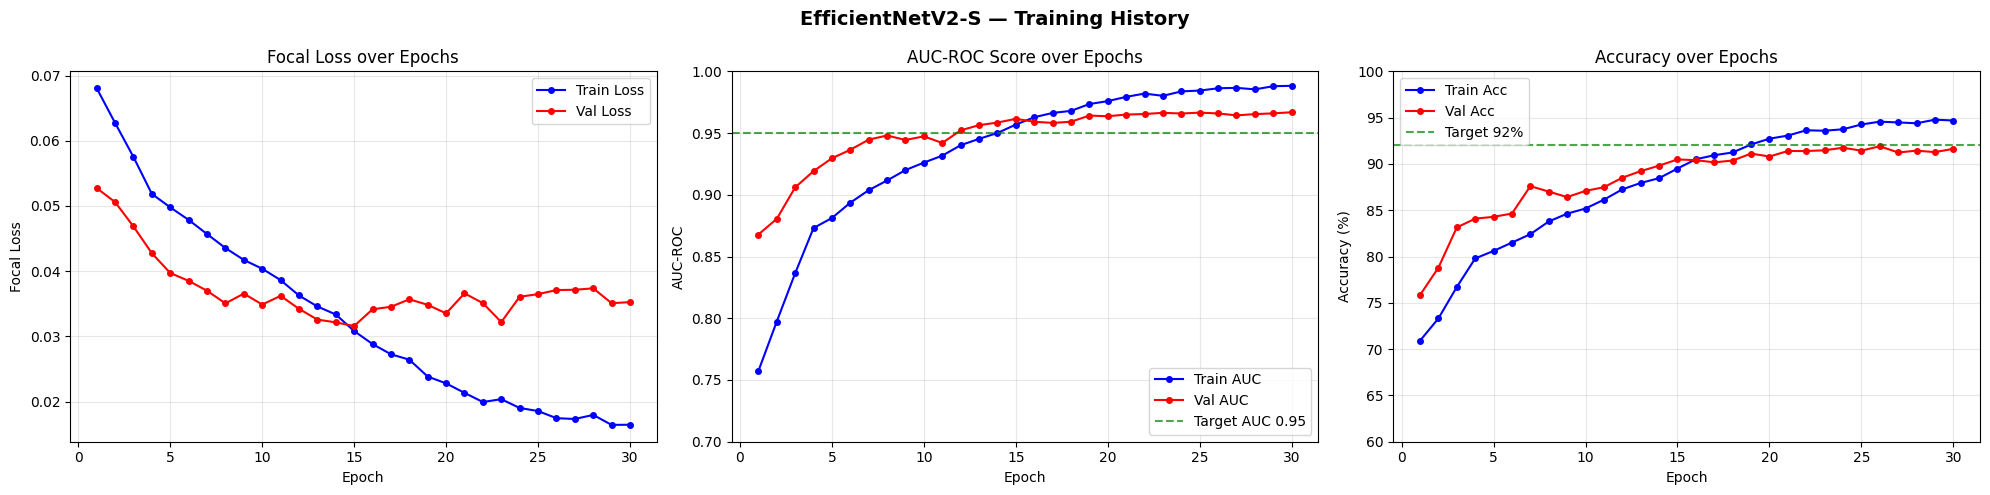

In [11]:
# ── CODE CELL 10: Plot Training Curves ───────────────────────
fig, axes = plt.subplots(1, 3, figsize=(20, 5))
fig.suptitle('EfficientNetV2-S — Training History', fontsize=14, fontweight='bold')
epochs_ran = range(1, len(history['train_loss']) + 1)

# Loss
axes[0].plot(epochs_ran, history['train_loss'], 'b-o', label='Train Loss', markersize=4)
axes[0].plot(epochs_ran, history['val_loss'],   'r-o', label='Val Loss',   markersize=4)
axes[0].set_title('Focal Loss over Epochs')
axes[0].set_xlabel('Epoch')
axes[0].set_ylabel('Focal Loss')
axes[0].legend()
axes[0].grid(alpha=0.3)

# AUC
axes[1].plot(epochs_ran, history['train_auc'], 'b-o', label='Train AUC', markersize=4)
axes[1].plot(epochs_ran, history['val_auc'],   'r-o', label='Val AUC',   markersize=4)
axes[1].axhline(y=0.95, color='green', linestyle='--', alpha=0.7, label='Target AUC 0.95')
axes[1].set_title('AUC-ROC Score over Epochs')
axes[1].set_xlabel('Epoch')
axes[1].set_ylabel('AUC-ROC')
axes[1].legend()
axes[1].grid(alpha=0.3)
axes[1].set_ylim([0.7, 1.0])

# ✔ NEW: Accuracy plot
axes[2].plot(epochs_ran, [a*100 for a in history['train_acc']], 'b-o', label='Train Acc', markersize=4)
axes[2].plot(epochs_ran, [a*100 for a in history['val_acc']],   'r-o', label='Val Acc',   markersize=4)
axes[2].axhline(y=92, color='green', linestyle='--', alpha=0.7, label='Target 92%')
axes[2].set_title('Accuracy over Epochs')
axes[2].set_xlabel('Epoch')
axes[2].set_ylabel('Accuracy (%)')
axes[2].legend()
axes[2].grid(alpha=0.3)
axes[2].set_ylim([60, 100])

plt.tight_layout()
plt.savefig(os.path.join(OUTPUT_DIR, 'efficientnetv2s_training_curves.png'),
            dpi=150, bbox_inches='tight')
plt.show()


## Final Evaluation on Test Set (Holdout)
We now load the **best saved weights** and evaluate on the test set
that was never seen during training — this is the true,
unbiased performance measurement.

In [12]:
# ── CODE CELL 11: Test Set Evaluation with TTA (FIXED) ───────────────────────────
checkpoint = torch.load(SAVE_PATH, map_location=DEVICE, weights_only=False)
model.load_state_dict(checkpoint['model_state_dict'])
print(f"✅ Loaded best checkpoint from epoch {checkpoint['epoch']}")

def predict_with_tta(model, loader, device):
    """Run TTA inference: average probs over original, h-flip, v-flip with metadata integrated."""
    model.eval()
    all_labels  = []
    all_probs_0 = []  
    all_probs_h = []  
    all_probs_v = []  

    with torch.no_grad():
        for images, meta, labels in tqdm(loader, desc="  TTA Inference", leave=False):
            images = images.to(device, non_blocking=True)
            meta   = meta.to(device, non_blocking=True)  # ✅ FIXED: Enforced explicit GPU metadata conversion
            labels = labels.to(device, non_blocking=True)

            with torch.amp.autocast('cuda'):
                # ✅ FIXED: Passed metadata tensor 'meta' into all three augmentation pathways
                logits_orig  = model(images, meta)
                logits_hflip = model(torch.flip(images, dims=[3]), meta)
                logits_vflip = model(torch.flip(images, dims=[2]), meta)

            all_probs_0.extend(torch.sigmoid(logits_orig).cpu().numpy())
            all_probs_h.extend(torch.sigmoid(logits_hflip).cpu().numpy())
            all_probs_v.extend(torch.sigmoid(logits_vflip).cpu().numpy())
            all_labels.extend(labels.cpu().numpy())

    probs_0 = np.array(all_probs_0)
    probs_h = np.array(all_probs_h)
    probs_v = np.array(all_probs_v)

    tta_probs = (probs_0 + probs_h + probs_v) / 3.0
    tta_labels = np.array(all_labels)
    tta_preds  = (tta_probs >= 0.5).astype(int)
    tta_auc    = roc_auc_score(tta_labels, tta_probs)
    tta_acc    = (tta_preds == tta_labels).mean()

    return tta_auc, tta_acc, tta_labels, tta_probs, tta_preds

# Run TTA on test set
test_auc, test_acc, test_labels, test_probs, test_preds = predict_with_tta(model, test_loader, DEVICE)

# ... Keep the metrics tables and matplotlib blocks below this unchanged

print("\n" + "=" * 60)
print("  EFFICIENTNETV2-S — TEST SET RESULTS (with TTA)")
print("=" * 60)
print(f"\n  AUC-ROC Score    : {test_auc:.4f}")
print(f"  Test Accuracy    : {test_acc*100:.2f}%")
print("\n  Classification Report:")
print(classification_report(test_labels, test_preds,
                             target_names=['Benign (0)', 'Malignant (1)'],
                             digits=4))

# ✔ Final summary block
print("=" * 60)
print("  SUMMARY TABLE")
print("=" * 60)
final_train_acc = history['train_acc'][-1] if history['train_acc'] else float('nan')
final_val_acc   = history['val_acc'][-1]   if history['val_acc']   else float('nan')
print(f"  {'Split':<12} {'AUC':>8} {'Accuracy':>12}")
print(f"  {'-'*34}")
print(f"  {'Train':<12} {history['train_auc'][-1]:>8.4f} {final_train_acc*100:>11.2f}%")
print(f"  {'Validation':<12} {best_val_auc:>8.4f} {final_val_acc*100:>11.2f}%")
print(f"  {'Test (TTA)':<12} {test_auc:>8.4f} {test_acc*100:>11.2f}%")
print("=" * 60)


✅ Loaded best checkpoint from epoch 30



  EFFICIENTNETV2-S — TEST SET RESULTS (with TTA)

  AUC-ROC Score    : 0.9657
  Test Accuracy    : 91.63%

  Classification Report:
               precision    recall  f1-score   support

   Benign (0)     0.9186    0.9519    0.9349      1600
Malignant (1)     0.9121    0.8555    0.8829       934

     accuracy                         0.9163      2534
    macro avg     0.9153    0.9037    0.9089      2534
 weighted avg     0.9162    0.9163    0.9157      2534

  SUMMARY TABLE
  Split             AUC     Accuracy
  ----------------------------------
  Train          0.9883       94.69%
  Validation     0.9669       91.63%
  Test (TTA)     0.9657       91.63%


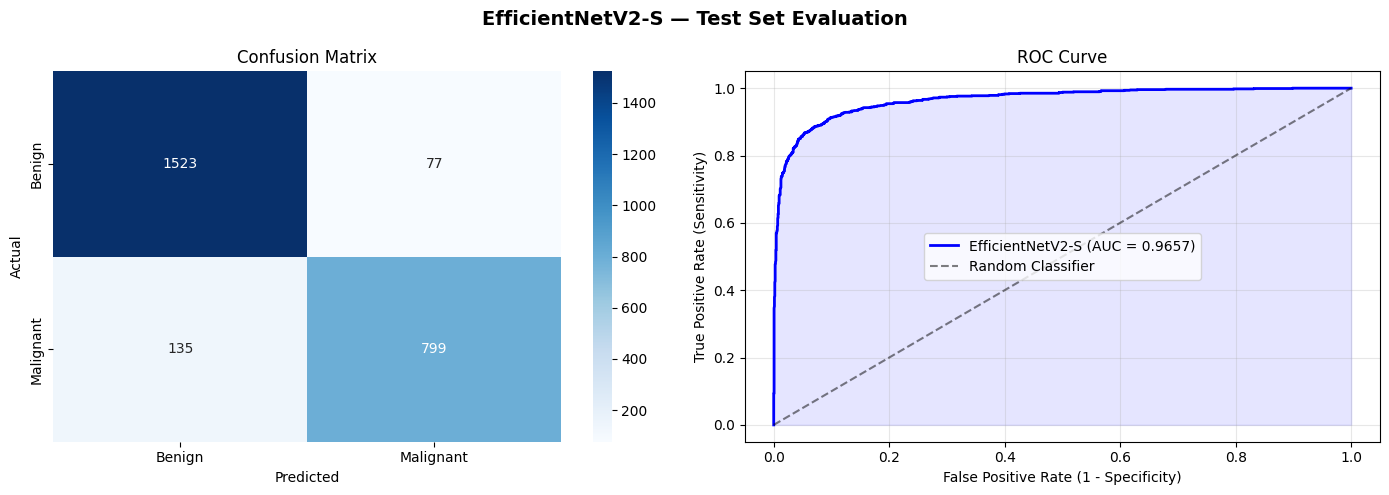


✅ Predictions saved for ensemble notebook.
   📁 efficientnetv2s_best.pth
   📁 efficientnetv2s_test_probs.npy


In [13]:
# ── CODE CELL 12: Confusion Matrix & ROC Curve ────────────────────────
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
fig.suptitle('EfficientNetV2-S — Test Set Evaluation', fontsize=14, fontweight='bold')

# Confusion Matrix
cm = confusion_matrix(test_labels, test_preds)
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', ax=axes[0],
            xticklabels=['Benign', 'Malignant'],
            yticklabels=['Benign', 'Malignant'])
axes[0].set_title('Confusion Matrix')
axes[0].set_xlabel('Predicted')
axes[0].set_ylabel('Actual')

# ROC Curve
fpr, tpr, _ = roc_curve(test_labels, test_probs)
axes[1].plot(fpr, tpr, 'b-', linewidth=2,
             label=f'EfficientNetV2-S (AUC = {test_auc:.4f})')
axes[1].plot([0, 1], [0, 1], 'k--', alpha=0.5, label='Random Classifier')
axes[1].fill_between(fpr, tpr, alpha=0.1, color='blue')
axes[1].set_title('ROC Curve')
axes[1].set_xlabel('False Positive Rate (1 - Specificity)')
axes[1].set_ylabel('True Positive Rate (Sensitivity)')
axes[1].legend()
axes[1].grid(alpha=0.3)

plt.tight_layout()
plt.savefig(os.path.join(OUTPUT_DIR, 'efficientnetv2s_evaluation.png'),
            dpi=150, bbox_inches='tight')
plt.show()

# Save predictions for Notebook 5
np.save(os.path.join(OUTPUT_DIR, 'efficientnetv2s_test_probs.npy'),
        np.array(test_probs))
np.save(os.path.join(OUTPUT_DIR, 'efficientnetv2s_test_labels.npy'),
        np.array(test_labels))

print(f"\n✅ Predictions saved for ensemble notebook.")
print(f"   📁 efficientnetv2s_best.pth")
print(f"   📁 efficientnetv2s_test_probs.npy")


In [14]:
# ── Val TTA → val_probs for Stacking Ensemble (FIXED) ──────────────────────────
model.eval()
tta_transforms_val = [
    lambda x: x,
    lambda x: torch.flip(x, dims=[3]),
    lambda x: torch.flip(x, dims=[2]),
]

val_all_probs, val_all_labels = [], []

with torch.no_grad():
    for images, meta, labels in tqdm(val_loader, desc='  Val TTA', leave=False):
        images = images.to(DEVICE, non_blocking=True)
        meta   = meta.to(DEVICE, non_blocking=True)  # ✅ FIXED: Transferred array reference to GPU accelerator
        
        batch_probs = torch.zeros(images.size(0), device=DEVICE)
        for tta_fn in tta_transforms_val:
            augmented = tta_fn(images)
            with torch.amp.autocast('cuda'):
                # ✅ FIXED: Appended metadata vector into the multimodal inference pass
                logits = model(augmented, meta)
            batch_probs += torch.sigmoid(logits)
            
        batch_probs /= len(tta_transforms_val)
        val_all_probs.extend(batch_probs.cpu().numpy())
        val_all_labels.extend(labels.numpy())

val_probs_arr  = np.array(val_all_probs)
val_labels_arr = np.array(val_all_labels).astype(int)

np.save(os.path.join(OUTPUT_DIR, 'efficientnetv2s_val_probs.npy'),  val_probs_arr)
np.save(os.path.join(OUTPUT_DIR, 'efficientnetv2s_val_labels.npy'), val_labels_arr)

print('All outputs saved for Stacking Ensemble:')
print(f'   efficientnetv2s_test_probs.npy   — {len(test_probs)} predictions')
print(f'   efficientnetv2s_val_probs.npy    — {len(val_probs_arr)} predictions')

All outputs saved for Stacking Ensemble:
   efficientnetv2s_test_probs.npy   — 2534 predictions
   efficientnetv2s_val_probs.npy    — 2533 predictions
